In [66]:
import pandas as pd
import numpy as np

These two libraries handle data loading, manipulation, and numerical operations throughout the notebook.


In [67]:
from wordcloud import WordCloud

Used later to generate a visual word cloud from the review text.

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer


matplotlib and seaborn are used for plotting (histograms, bar charts, confusion matrices).
TfidfVectorizer will later convert cleaned text into numerical features for modeling.

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.model_selection import train_test_split

LogisticRegression is our sentiment classification model.
LatentDirichletAllocation (LDA) can be used for topic modeling to identify key themes.
train_test_split divides the data into training and testing sets.

In [70]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

These metrics will be used later to evaluate how well the trained model performs.

In [71]:
df = pd.read_csv(r"C:\Users\vhona\Downloads\Reviews.csv")
df.head() 

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


Loads the Amazon Fine Food Reviews dataset from the local file path and displays the first 5 rows to confirm it loaded correctly.

In [72]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


Text Cleaning Setup

In [73]:
df.isnull().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

In [74]:
df.duplicated(subset=['Text']).sum()
df = df.drop_duplicates(subset=['Text'])

Removes any rows with missing review text, and drops duplicate reviews so repeated content doesn't bias the analysis.

In [75]:
import re
import string

In [76]:
import re
import string
import pandas as pd
import nltk
from nltk.corpus import stopwords

re and string are used to remove HTML tags and punctuation from review text.
nltk provides the list of English stopwords needed to clean the text further.

In [27]:
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)

True

Downloads the required NLTK resources. These only need to download once; NLTK will confirm if they're already up to date.

In [28]:
df = pd.read_csv(r"C:\Users\vhona\Downloads\Reviews.csv")

In [29]:
print(df.shape)
print(df.columns)
df.head()

(568454, 10)
Index(['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator',
       'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text'],
      dtype='object')


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [30]:
df = df.dropna(subset=['Text'])          
df = df.drop_duplicates(subset=['Text']) 


Removes any rows with missing review text, and drops duplicate reviews so repeated content doesn't bias the analysis.

In [31]:
stop_words = set(stopwords.words('english'))

Creates a set of common English stopwords (e.g. "the", "is", "and") to filter out during cleaning.

In [32]:
def clean_text(text):
    text = text.lower()                                    
    text = re.sub(r'<.*?>', '', text)                       
    text = text.translate(str.maketrans('', '', string.punctuation))  
    text = ' '.join([w for w in text.split() if w not in stop_words]) 
    return text

This function lowercases the text, strips out HTML tags and punctuation, and removes stopwords, returning a cleaned version of each review.

In [33]:
df['clean_text'] = df['Text'].apply(clean_text)
df[['Text', 'clean_text']].head()

,Text,clean_text
0,I have bought several of the Vitality canned d...,bought several vitality canned dog food produc...
1,Product arrived labeled as Jumbo Salted Peanut...,product arrived labeled jumbo salted peanutsth...
2,This is a confection that has been around a fe...,confection around centuries light pillowy citr...
3,If you are looking for the secret ingredient i...,looking secret ingredient robitussin believe f...
4,Great taffy at a great price. There was a wid...,great taffy great price wide assortment yummy ...


Applies the cleaning function to every review and displays the original vs. cleaned text side-by-side to verify it worked as expected.

In [34]:
df_sample = df.sample(n=20000, random_state=42).reset_index(drop=True)

Takes a random sample of 20,000 reviews to keep the pipeline fast and manageable while testing, with random_state=42 ensuring the same sample every run.

In [35]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter


matplotlib and seaborn handle all plotting (histograms, bar charts, confusion matrices).
TfidfVectorizer will later convert cleaned text into numerical features for modeling.


In [36]:
def label_sentiment(score):
    if score <= 2:
        return 'negative'
    elif score == 3:
        return 'neutral'
    else:
        return 'positive'

Converts the numeric star rating (1-5) into a sentiment category:
1-2 stars = negative, 3 stars = neutral, 4-5 stars = positive.


In [37]:
df_sample['sentiment'] = df_sample['Score'].apply(label_sentiment)
print(df_sample['sentiment'].value_counts())

sentiment
positive    15605
negative     2920
neutral      1475
Name: count, dtype: int64


Applies the labeling function to every review and prints the class distribution.
The output shows a strong imbalance (positive reviews far outnumber negative and neutral ones),
which is important context for model evaluation later.

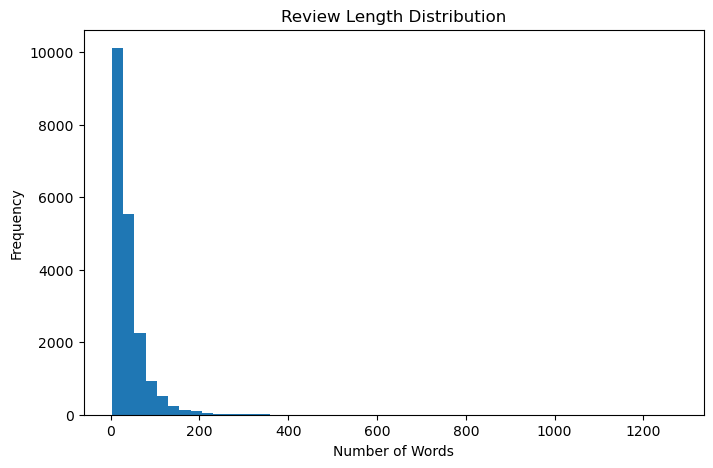

In [38]:
df_sample['review_length'] = df_sample['clean_text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(8, 5))
plt.hist(df_sample['review_length'], bins=50)
plt.title('Review Length Distribution')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()

Plots a histogram showing how review lengths are distributed across the dataset,
which helps identify whether most reviews are short or long, and highlights potential outliers.


In [39]:
all_words = ' '.join(df_sample['clean_text']).split()
word_freq = Counter(all_words).most_common(20)
words, counts = zip(*word_freq)

Combines all cleaned reviews into one long list of words, then counts
how often each word appears, keeping only the 20 most frequent.

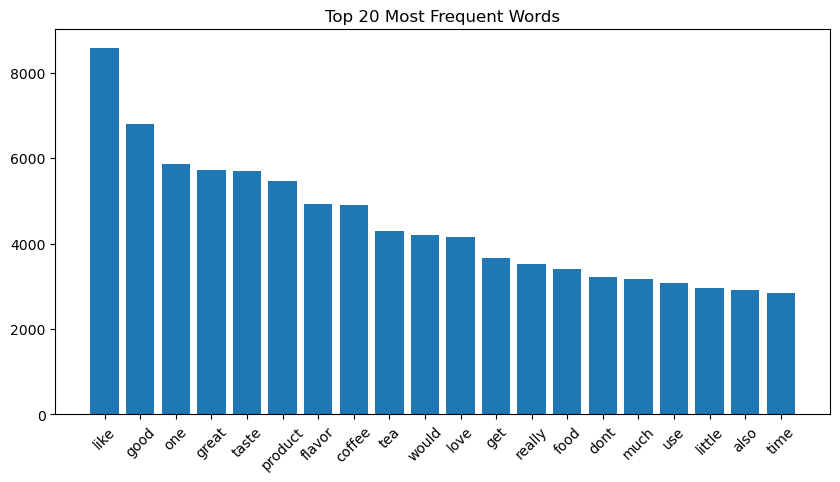

In [40]:
plt.figure(figsize=(10, 5))
plt.bar(words, counts)
plt.xticks(rotation=45)
plt.title('Top 20 Most Frequent Words')
plt.show()

Visualizes the most common words across all reviews as a bar chart,
giving an early indication of recurring themes (e.g. "taste", "product", "good").

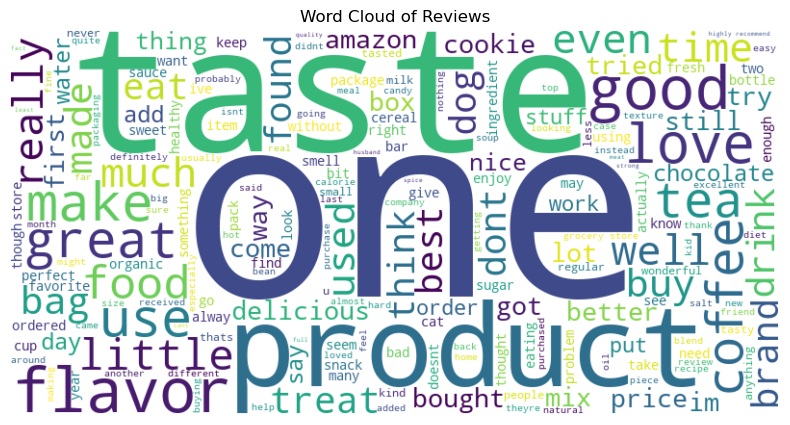

In [41]:
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_words_text := ' '.join(df_sample['clean_text']))
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Reviews')
plt.show()

Generates a word cloud where larger words appear more frequently across the reviews,
offering a quick visual summary of dominant themes such as "taste", "flavor", and "product".


In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer


Imported here again ahead of the feature engineering step below.

In [43]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X = tfidf.fit_transform(df_sample['clean_text'])
y = df_sample['sentiment']

print(X.shape)

(20000, 5000)


Converts the cleaned review text into numerical TF-IDF features, capturing both
single words and two-word phrases (bigrams), limited to the top 5000 most informative terms.
X holds the feature matrix (20000 reviews x 5000 features) and y holds the sentiment labels.


In [44]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

Imports needed for splitting the data and training both candidate models.

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


Splits the data into 80% training and 20% testing, using stratify=y so that
the proportion of negative/neutral/positive reviews stays consistent across both sets.


In [46]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


Trains a Logistic Regression model on the training data.

In [47]:
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


Trains a Naive Bayes model on the same training data, to compare performance against Logistic Regression.

In [48]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

Imports the metrics needed to evaluate both trained models.

In [49]:
y_pred_log = log_reg.predict(X_test)
y_pred_nb = nb_model.predict(X_test)

Generates predictions on the unseen test set for both models.

In [50]:
print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print(classification_report(y_test, y_pred_log))


Logistic Regression Results
Accuracy: 0.8465
              precision    recall  f1-score   support

    negative       0.77      0.51      0.61       584
     neutral       0.46      0.08      0.13       295
    positive       0.86      0.98      0.92      3121

    accuracy                           0.85      4000
   macro avg       0.70      0.52      0.55      4000
weighted avg       0.82      0.85      0.81      4000



Prints overall accuracy plus precision, recall, and F1-score per class for Logistic Regression.

In [51]:
print("Naive Bayes Results")
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb))

Naive Bayes Results
Accuracy: 0.81025
              precision    recall  f1-score   support

    negative       0.88      0.22      0.35       584
     neutral       0.00      0.00      0.00       295
    positive       0.81      1.00      0.89      3121

    accuracy                           0.81      4000
   macro avg       0.56      0.41      0.41      4000
weighted avg       0.76      0.81      0.75      4000



C:\Users\vhona\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\vhona\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\vhona\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Prints the same set of metrics for Naive Bayes, to allow a direct comparison between the two models.

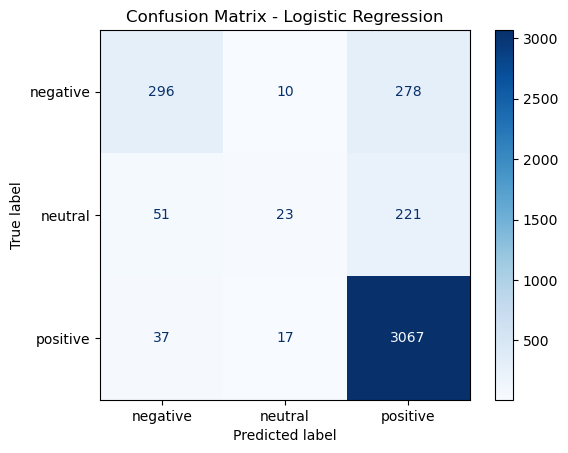

In [52]:
cm = confusion_matrix(y_test, y_pred_log, labels=log_reg.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=log_reg.classes_)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

Visualizes where Logistic Regression's predictions matched or missed the true sentiment labels,
making it easy to see which classes (e.g. neutral) are most often misclassified.

In [53]:
log_reg_balanced = LogisticRegression(max_iter=1000, class_weight='balanced')
log_reg_balanced.fit(X_train, y_train)
y_pred_balanced = log_reg_balanced.predict(X_test)

In [54]:
print("Logistic Regression (Balanced) Results")
print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print(classification_report(y_test, y_pred_balanced))


Logistic Regression (Balanced) Results
Accuracy: 0.775
              precision    recall  f1-score   support

    negative       0.55      0.71      0.62       584
     neutral       0.24      0.47      0.32       295
    positive       0.95      0.82      0.88      3121

    accuracy                           0.78      4000
   macro avg       0.58      0.66      0.61      4000
weighted avg       0.84      0.78      0.80      4000



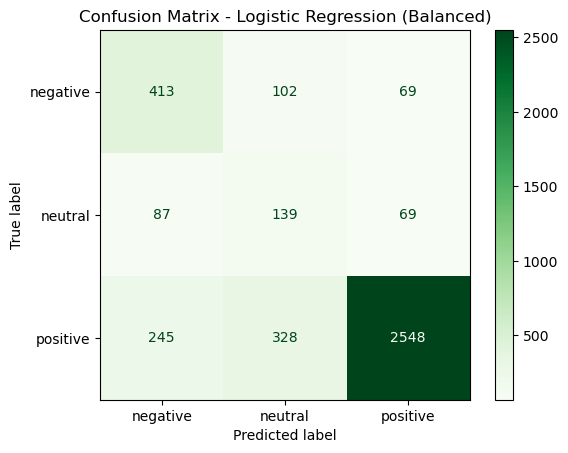

In [55]:
cm_balanced = confusion_matrix(y_test, y_pred_balanced, labels=log_reg_balanced.classes_)
disp_balanced = ConfusionMatrixDisplay(confusion_matrix=cm_balanced, display_labels=log_reg_balanced.classes_)
disp_balanced.plot(cmap='Greens')
plt.title('Confusion Matrix - Logistic Regression (Balanced)')
plt.show()

Visualizes where Logistic Regression's predictions matched or missed the true sentiment labels,
making it easy to see which classes (e.g. neutral) are most often misclassified.

In [56]:
Q1 = df_sample['review_length'].quantile(0.25)
Q3 = df_sample['review_length'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [57]:
outliers = df_sample[(df_sample['review_length'] < lower_bound) | (df_sample['review_length'] > upper_bound)]
print(f"Number of outlier reviews: {len(outliers)}")
print(f"Outlier bounds: {lower_bound:.1f} to {upper_bound:.1f} words")

Number of outlier reviews: 1362
Outlier bounds: -31.0 to 97.0 words


In [58]:
print(df_sample[['HelpfulnessNumerator', 'HelpfulnessDenominator']].corr())

                        HelpfulnessNumerator  HelpfulnessDenominator
HelpfulnessNumerator                 1.00000                 0.97474
HelpfulnessDenominator               0.97474                 1.00000


In [59]:
df_sample['helpfulness_ratio'] = df_sample['HelpfulnessNumerator'] / df_sample['HelpfulnessDenominator'].replace(0, np.nan)
df_sample['helpfulness_ratio'] = df_sample['helpfulness_ratio'].fillna(0)

In [60]:
for test_size in [0.2, 0.25]:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )
    model = LogisticRegression(max_iter=1000, class_weight='balanced')
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    print(f"Test size {test_size}: Accuracy = {accuracy_score(y_te, preds):.3f}")

Test size 0.2: Accuracy = 0.775
Test size 0.25: Accuracy = 0.782


In [61]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [62]:
log_reg_balanced = LogisticRegression(max_iter=1000, class_weight='balanced')
log_reg_balanced.fit(X_train, y_train)
y_pred_log = log_reg_balanced.predict(X_test)



Prints overall accuracy plus precision, recall, and F1-score per class for Logistic Regression.

In [63]:
sentiment_map = {'negative': 0, 'neutral': 1, 'positive': 2}


In [64]:
y_test_num = y_test.map(sentiment_map)
y_pred_log_num = pd.Series(y_pred_log).map(sentiment_map)

Generates predictions on the unseen test set for both models.

In [78]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

Imports the regression-style metrics used to measure how "far off" misclassifications are.

In [79]:
sentiment_map = {'negative': 0, 'neutral': 1, 'positive': 2}

y_test_num = y_test.map(sentiment_map)
y_pred_log_num = pd.Series(y_pred_log).map(sentiment_map)

Maps the three sentiment labels to ordinal numbers (0, 1, 2) so that MAE and RMSE can be calculated.
This treats a negative-vs-positive confusion as a bigger error than a negative-vs-neutral confusion.


In [80]:
mae_log = mean_absolute_error(y_test_num, y_pred_log_num)
rmse_log = np.sqrt(mean_squared_error(y_test_num, y_pred_log_num))
print("Logistic Regression - MAE:", mae_log, "RMSE:", rmse_log)

Logistic Regression - MAE: 0.3035 RMSE: 0.6786015030929419


Calculates the average size of prediction errors (MAE) and a metric that penalizes larger
errors more heavily (RMSE), giving a complementary view of model performance beyond accuracy.

1. Class Imbalance Bias
The sentiment distribution (from df_sample['sentiment'].value_counts()) showed roughly
15,605 positive, 2,920 negative, and 1,475 neutral reviews. This heavy skew toward positive
reviews means the models are trained mostly on positive examples, which explains why
Naive Bayes in particular struggled to predict negative and neutral reviews (0.00 precision/recall
or neutral). Logistic Regression's class_weight='balanced' setting partially corrected for this
by penalizing misclassification of minority classes more heavily.

2. Selection Bias
Reviewers are self-selected: customers who are either extremely satisfied or extremely
dissatisfied are more likely to leave a review than those with a moderate, neutral opinion.
This likely explains why neutral reviews are so underrepresented in the dataset, and means
the dataset may not reflect the true distribution of customer sentiment overall, only the
opinions of those motivated enough to write a review.

3. Label Bias
Sentiment labels were derived directly from the numeric star rating (Score), not from the
review text itself. This assumes ratings and text always agree, but in practice a customer
may leave a harshly worded review with a 3-star rating, or a glowing review with a 4-star
rating due to a minor issue. This mismatch introduces label noise that the model has no way
to detect or correct, since it only learns from the assumed label.

 4. Model Bias (downstream effect of the above)
Because the model is trained on imbalanced and potentially mislabeled data, it inherits a
bias toward predicting "positive" sentiment. This is reflected in the high overall accuracy
scores (0.81-0.85) which are misleadingly inflated by the dominant positive class, while
per-class recall for negative and neutral reviews remains comparatively low.

Mitigation applied: class_weight='balanced' in Logistic Regression partially addresses
class imbalance bias. Selection bias and label bias are structural limitations of the
dataset itself and would require more representative data collection (e.g. surveying a
random sample of all customers, not just those who chose to review) or human-verified
sentiment labels to fully resolve.